# 02. Punkt odniesienia: prosta sieć CNN uczona od zera

Model `SimpleCNN` (`src/models.py`): 4 bloki [Conv 3x3 - BN - ReLU] x 2 + MaxPool
(32, 64, 128, 256 filtrów), globalne uśrednianie, dropout 0.3 i warstwa liniowa na 4 klasy.
Wejście: jeden kanał szarości znormalizowany średnią i odchyleniem zbioru treningowego
(0.18 i 0.20, z notatnika 01). Ok. 1,2 mln parametrów.

Po co ten model? Pokazuje, ile daje transfer learning (notatnik 03) w porównaniu z siecią,
która uczy się wszystkiego od zera na 5500 obrazach.

Trening: `scripts/run_cv.sh` -> `python -m src.train cv --model cnn` (w tle, ok. 27 minut na
RTX 4060). Tutaj tylko wczytujemy zapisane wyniki.

Ustawienia wspólne dla wszystkich modeli:
- **Stratified Group K-Fold, K = 5** na 5500 obrazach treningowych (grupy niemal-duplikatów
  z notatnika 01 nie są rozdzielane między foldy),
- AdamW, harmonogram kosinusowy LR, entropia krzyżowa, mieszana precyzja bf16,
- augmentacja: odbicie w poziomie, obrót do 10 stopni, przesunięcie do 5%, skala 0.9-1.1,
- po każdej epoce macro-F1 na walidacji; zapamiętujemy wagi **najlepszej** epoki,
- stałe ziarno (42 + numer foldu).

In [1]:
import sys
sys.path.insert(0, '..')

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import FIG_DIR, METRICS_DIR

cv = json.load(open(METRICS_DIR / 'cv_cnn.json'))
print(cv['params'])
folds = pd.DataFrame([{k: v for k, v in f.items() if k != 'history'} for f in cv['folds']])
folds.round(4)

{'lr': 0.001, 'weight_decay': 0.0001, 'dropout': 0.3, 'batch_size': 32, 'epochs': 30, 'head_epochs': 0, 'n_unfreeze': 0}


,fold,best_epoch,accuracy,macro_f1,macro_recall,macro_specificity,macro_auc
0,0,28,0.9609,0.9603,0.9602,0.9870,0.9953
1,1,30,0.9455,0.9449,0.9451,0.9820,0.9949
2,2,30,0.9564,0.9556,0.9556,0.9855,0.9919
3,3,27,0.9573,0.9570,0.9571,0.9859,0.9948
4,4,28,0.9573,0.9569,0.9569,0.9858,0.9957


In [2]:
cols = ['accuracy', 'macro_f1', 'macro_recall', 'macro_specificity', 'macro_auc']
pd.DataFrame({'średnia': folds[cols].mean(), 'odch. std': folds[cols].std()}).round(4)

,średnia,odch. std
accuracy,0.9555,0.0059
macro_f1,0.9549,0.0059
macro_recall,0.9550,0.0058
macro_specificity,0.9852,0.0019
macro_auc,0.9945,0.0015


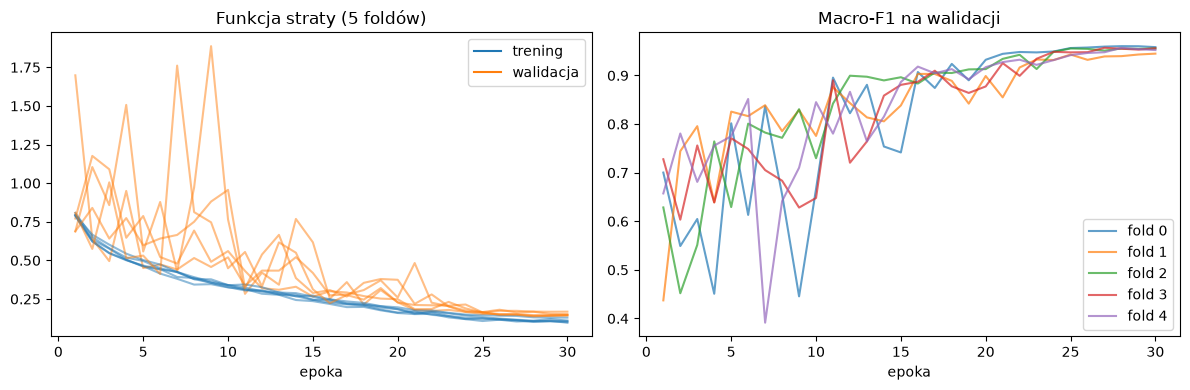

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for f in cv['folds']:
    h = pd.DataFrame(f['history'])
    axes[0].plot(h.epoch, h.train_loss, color='tab:blue', alpha=0.5)
    axes[0].plot(h.epoch, h.val_loss, color='tab:orange', alpha=0.5)
    axes[1].plot(h.epoch, h.val_macro_f1, alpha=0.7, label=f"fold {f['fold']}")
axes[0].plot([], [], color='tab:blue', label='trening')
axes[0].plot([], [], color='tab:orange', label='walidacja')
axes[0].set_title('Funkcja straty (5 foldów)')
axes[0].set_xlabel('epoka')
axes[0].legend()
axes[1].set_title('Macro-F1 na walidacji')
axes[1].set_xlabel('epoka')
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'cv_cnn_krzywe.png', dpi=150)
plt.show()

## Interpretacja
- Średnie macro-F1 z 5 foldów to ok. 0,955 przy małym rozrzucie między foldami (odchylenie ok. 0,006).
- W pierwszych 15 epokach strata walidacyjna mocno skacze, a macro-F1 waha się między 0,4 a 0,9.
  To typowe dla sieci uczonej od zera z dużym LR (1e-3) i normalizacją wsadową: statystyki BN
  zmieniają się szybko. Gdy harmonogram kosinusowy zmniejsza LR, uczenie się stabilizuje.
- Najlepsza epoka wypada pod koniec (27-30 z 30), więc model końcowy uczymy pełne 30 epok.
  Dłuższy trening mógłby jeszcze trochę pomóc, ale CNN jest tu tylko punktem odniesienia.
- Strata treningowa i walidacyjna kończą na podobnym poziomie, więc nie widać silnego przeuczenia.
- Wynik na poziomie 95% pokazuje, że zadanie jest „łatwe” nawet dla małej sieci. To pasuje do
  obserwacji z EDA: klasy różnią się także źródłem, rozmiarem i jasnością obrazu, nie tylko guzem.